
# Proyecto de Ciencia de Datos

## Análisis y predicción del rendimiento académico

**Estudiante:** Pendiente de completar

**Carrera:** Ingeniería de Sistemas

**Modalidad:** Individual

**Curso:** Ciencia de Datos

**Herramientas:** Python, Google Colab, Pandas, NumPy, Matplotlib y Scikit-learn.

## Descripción

Este proyecto busca analizar los factores relacionados con el rendimiento académico de los estudiantes mediante técnicas de ciencia de datos.

Se utilizarán herramientas de exploración, limpieza, estadística descriptiva, visualización y regresión lineal para comprender el comportamiento de los datos y desarrollar un modelo predictivo.



In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [73]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Librerías de Machine Learning importadas correctamente")

Librerías de Machine Learning importadas correctamente


In [74]:
import requests
import zipfile
import io
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

respuesta = requests.get(url)
respuesta.raise_for_status()

# Abrimos el archivo ZIP principal descargado
with zipfile.ZipFile(io.BytesIO(respuesta.content)) as archivo_principal:
    # Extraemos el archivo student.zip que está dentro del principal
    with archivo_principal.open("student.zip") as archivo_interno_zip:
        # Abrimos el student.zip interno en memoria
        with zipfile.ZipFile(io.BytesIO(archivo_interno_zip.read())) as archivo_interno:
            # Ahora sí podemos acceder a student-mat.csv
            with archivo_interno.open("student-mat.csv") as datos:
                df = pd.read_csv(datos, sep=";")

print("sirve")

sirve


In [75]:
print("Primeros cinco registros:")

display(df.head())


Primeros cinco registros:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [76]:
print("Cantidad de filas y columnas:")
print(df.shape)

print("\nInformación general:")
df.info()

print("\nEstadísticas descriptivas:")
display(df.describe())

print("\nTipos de variables:")
display(df.dtypes)


Cantidad de filas y columnas:
(395, 33)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000



Tipos de variables:


,0
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


In [77]:
# Contar valores nulos por columna
nulos_por_columna = df.isnull().sum()

display(nulos_por_columna[nulos_por_columna > 0])

# Total de valores nulos
total_nulos = df.isnull().sum().sum()

print("Total de valores nulos:", total_nulos)

# Revisar las primeras filas
display(df.head())


,0


Total de valores nulos: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [78]:
print("Valores nulos por columna:")
display(df.isnull().sum())

# Total de valores nulos
print("\nTotal de valores nulos:")
print(df.isnull().sum().sum())

# Registros duplicados
print("\nCantidad de duplicados:")
print(df.duplicated().sum())

# Cantidad de valores únicos
print("\nValores únicos por variable:")
display(df.nunique())


Valores nulos por columna:


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0



Total de valores nulos:
0

Cantidad de duplicados:
0

Valores únicos por variable:


,0
school,2
sex,2
age,8
address,2
famsize,2
Pstatus,2
Medu,5
Fedu,5
Mjob,5
Fjob,5


In [79]:
df_limpio = df.copy()

# Eliminar duplicados, si existen
df_limpio = df_limpio.drop_duplicates()

print("Dimensiones originales:", df.shape)
print("Dimensiones después de eliminar duplicados:", df_limpio.shape)

print("Valores nulos restantes:",
      df_limpio.isnull().sum().sum())

Dimensiones originales: (395, 33)
Dimensiones después de eliminar duplicados: (395, 33)
Valores nulos restantes: 0


In [80]:
# Crear una copia del dataset original
df_limpio = df.copy()

# Eliminar registros duplicados
df_limpio = df_limpio.drop_duplicates()

# Verificar valores nulos
total_nulos = df_limpio.isnull().sum().sum()

# Verificar duplicados
total_duplicados = df_limpio.duplicated().sum()

# Mostrar resultados
print("RESULTADOS DE LA LIMPIEZA")
print("-------------------------")
print("Filas originales:", df.shape[0])
print("Columnas originales:", df.shape[1])
print("Filas después de limpieza:", df_limpio.shape[0])
print("Columnas después de limpieza:", df_limpio.shape[1])
print("Valores nulos:", total_nulos)
print("Duplicados:", total_duplicados)

RESULTADOS DE LA LIMPIEZA
-------------------------
Filas originales: 395
Columnas originales: 33
Filas después de limpieza: 395
Columnas después de limpieza: 33
Valores nulos: 0
Duplicados: 0


In [81]:
# Exportar dataset limpio
df_limpio.to_csv(
    "student_mat_limpio.csv",
    index=False,
    encoding="utf-8"
)

print("Archivo limpio guardado correctamente.")

Archivo limpio guardado correctamente.


In [82]:
from google.colab import files

files.download("student_mat_limpio.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [83]:
# Estadísticas generales de las calificaciones
display(
    df_limpio[["G1", "G2", "G3"]].describe()
)

,G1,G2,G3
count,395.000000,395.000000,395.000000
mean,10.908861,10.713924,10.415190
std,3.319195,3.761505,4.581443
min,3.000000,0.000000,0.000000
25%,8.000000,9.000000,8.000000
50%,11.000000,11.000000,11.000000
75%,13.000000,13.000000,14.000000
max,19.000000,19.000000,20.000000


In [84]:
# Medidas de tendencia central
calificaciones = ["G1", "G2", "G3"]

for columna in calificaciones:
    print("\nVariable:", columna)
    print("Media:", df_limpio[columna].mean())
    print("Mediana:", df_limpio[columna].median())
    print("Moda:", df_limpio[columna].mode().tolist())


Variable: G1
Media: 10.90886075949367
Mediana: 11.0
Moda: [10]

Variable: G2
Media: 10.713924050632912
Mediana: 11.0
Moda: [9]

Variable: G3
Media: 10.415189873417722
Mediana: 11.0
Moda: [10]


In [85]:
# Medidas de dispersión
for columna in calificaciones:
    datos = df_limpio[columna]

    print("\nVariable:", columna)
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Rango:", datos.max() - datos.min())
    print("Varianza:", datos.var())
    print("Desviación estándar:", datos.std())


Variable: G1
Mínimo: 3
Máximo: 19
Rango: 16
Varianza: 11.017053267364899
Desviación estándar: 3.3191946715076686

Variable: G2
Mínimo: 0
Máximo: 19
Rango: 19
Varianza: 14.148917303861756
Desviación estándar: 3.761504659556034

Variable: G3
Mínimo: 0
Máximo: 20
Rango: 20
Varianza: 20.989616397866737
Desviación estándar: 4.5814426109978434


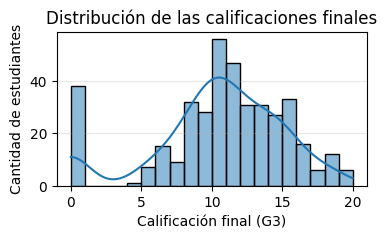

In [86]:
plt.figure(figsize=(4, 2))

sns.histplot(
    data=df_limpio,
    x="G3",
    bins=20,
    kde=True
)

plt.title("Distribución de las calificaciones finales")
plt.xlabel("Calificación final (G3)")
plt.ylabel("Cantidad de estudiantes")
plt.grid(axis="y", alpha=0.3)

plt.show()

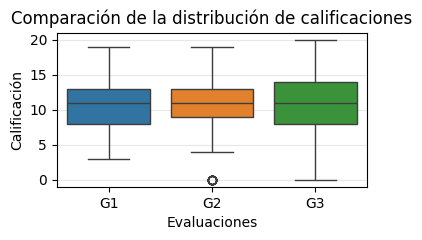

In [87]:
plt.figure(figsize=(4, 2))

sns.boxplot(data=df_limpio[["G1", "G2", "G3"]])

plt.title("Comparación de la distribución de calificaciones")
plt.xlabel("Evaluaciones")
plt.ylabel("Calificación")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [88]:
for columna in ["G1", "G2", "G3"]:

    Q1 = df_limpio[columna].quantile(0.25)
    Q3 = df_limpio[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    atipicos = df_limpio[
        (df_limpio[columna] < limite_inferior) |
        (df_limpio[columna] > limite_superior)
    ]

    print("\nVariable:", columna)
    print("Límite inferior:", limite_inferior)
    print("Límite superior:", limite_superior)
    print("Cantidad de valores atípicos:", len(atipicos))


Variable: G1
Límite inferior: 0.5
Límite superior: 20.5
Cantidad de valores atípicos: 0

Variable: G2
Límite inferior: 3.0
Límite superior: 19.0
Cantidad de valores atípicos: 13

Variable: G3
Límite inferior: -1.0
Límite superior: 23.0
Cantidad de valores atípicos: 0


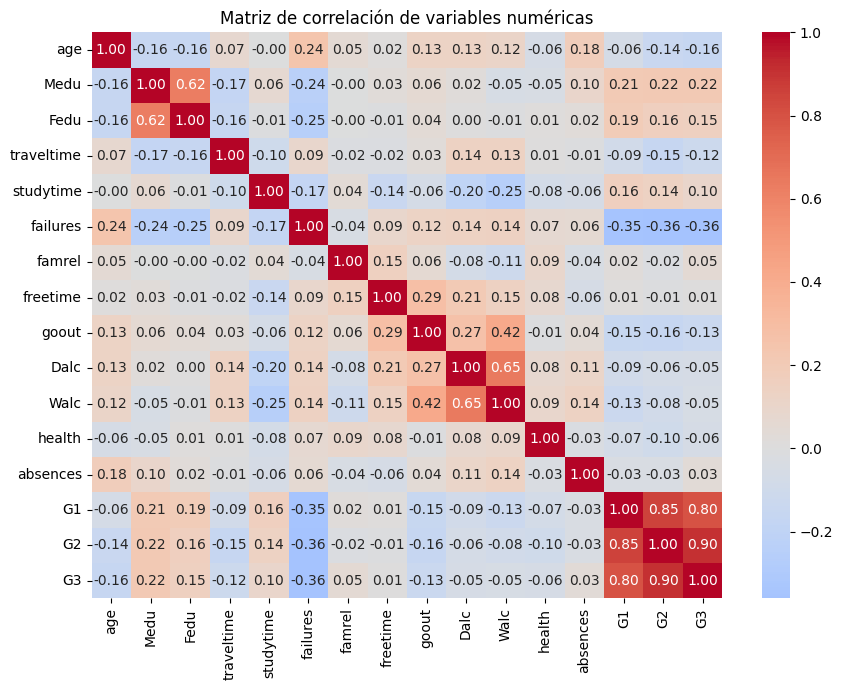

In [89]:
# Seleccionar variables numéricas
df_numerico = df_limpio.select_dtypes(include="number")

# Calcular matriz de correlación
matriz_corr = df_numerico.corr()

# Visualizar la matriz
plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

In [90]:
# Correlaciones con la calificación final
correlaciones_g3 = (
    matriz_corr["G3"]
    .drop("G3")
    .sort_values(ascending=False)
)

print("CORRELACIONES CON LA NOTA FINAL (G3)")
print(correlaciones_g3.round(3))

CORRELACIONES CON LA NOTA FINAL (G3)
G2            0.905
G1            0.801
Medu          0.217
Fedu          0.152
studytime     0.098
famrel        0.051
absences      0.034
freetime      0.011
Walc         -0.052
Dalc         -0.055
health       -0.061
traveltime   -0.117
goout        -0.133
age          -0.162
failures     -0.360
Name: G3, dtype: float64


In [91]:
import numpy as np
import matplotlib.pyplot as plt

# Variables
x = df_limpio["studytime"].to_numpy(dtype=float)
y = df_limpio["G3"].to_numpy(dtype=float)

n = len(x)

# Sumatorias
sumx = np.sum(x)
sumy = np.sum(y)
sumx2 = np.sum(x**2)
sumxy = np.sum(x*y)

# Promedios
promx = sumx / n
promy = sumy / n

# Pendiente e intercepto
m = (n*sumxy - sumx*sumy) / (n*sumx2 - sumx**2)
b = promy - m*promx

# Predicciones
y_pred = m*x + b

# Coeficiente de determinación
ss_res = np.sum((y - y_pred)**2)
ss_tot = np.sum((y - promy)**2)

R2 = 1 - ss_res/ss_tot

print("RESULTADOS REGRESIÓN LINEAL")
print("--------------------------")
print("Pendiente:", round(m, 4))
print("Intercepto:", round(b, 4))
print("R²:", round(R2, 4))
print(f"Ecuación: G3 = {m:.4f} * studytime + {b:.4f}")

RESULTADOS REGRESIÓN LINEAL
--------------------------
Pendiente: 0.534
Intercepto: 9.3283
R²: 0.0096
Ecuación: G3 = 0.5340 * studytime + 9.3283


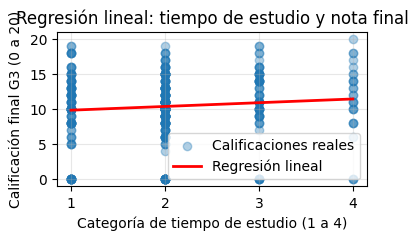

In [92]:
plt.figure(figsize=(4, 2))

plt.scatter(
    x, y,
    alpha=0.35,
    label="Calificaciones reales"
)

x_linea = np.linspace(x.min(), x.max(), 100)
y_linea = m*x_linea + b

plt.plot(
    x_linea, y_linea,
    color="red",
    linewidth=2,
    label="Regresión lineal"
)

plt.title("Regresión lineal: tiempo de estudio y nota final")
plt.xlabel("Categoría de tiempo de estudio (1 a 4)")
plt.ylabel("Calificación final G3 (0 a 20)")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [93]:
# Modelo A: sin calificaciones anteriores
variables_A = [
    "age", "studytime", "failures", "absences",
    "schoolsup", "famsup", "paid", "activities",
    "internet", "health", "goout", "freetime"
]

# Modelo B: incorpora las calificaciones anteriores
variables_B = variables_A + ["G1", "G2"]

# Variable objetivo
y = df_limpio["G3"]

X_A = df_limpio[variables_A]
X_B = df_limpio[variables_B]

print("Modelo A:", X_A.shape)
print("Modelo B:", X_B.shape)
print("Variable objetivo:", y.shape)

Modelo A: (395, 12)
Modelo B: (395, 14)
Variable objetivo: (395,)


In [94]:
indices_train, indices_test = train_test_split(
    df_limpio.index,
    test_size=0.20,
    random_state=42
)

X_A_train = X_A.loc[indices_train]
X_A_test = X_A.loc[indices_test]

X_B_train = X_B.loc[indices_train]
X_B_test = X_B.loc[indices_test]

y_train = y.loc[indices_train]
y_test = y.loc[indices_test]

print("Estudiantes de entrenamiento:", len(y_train))
print("Estudiantes de prueba:", len(y_test))

Estudiantes de entrenamiento: 316
Estudiantes de prueba: 79


In [95]:
def crear_modelo(X):

    numericas = X.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categoricas = X.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    preprocesamiento = ColumnTransformer(
        transformers=[
            (
                "num",
                SimpleImputer(strategy="median"),
                numericas
            ),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(
                        strategy="most_frequent"
                    )),
                    ("encoder", OneHotEncoder(
                        handle_unknown="ignore"
                    ))
                ]),
                categoricas
            )
        ]
    )

    modelo = Pipeline([
        ("preprocesamiento", preprocesamiento),
        ("regresion", LinearRegression())
    ])

    return modelo


# Crear modelos
modelo_A = crear_modelo(X_A_train)
modelo_B = crear_modelo(X_B_train)

# Entrenamiento
modelo_A.fit(X_A_train, y_train)
modelo_B.fit(X_B_train, y_train)

print("Modelos entrenados correctamente")

Modelos entrenados correctamente


In [96]:
# Predicciones sobre los datos de prueba
pred_A = modelo_A.predict(X_A_test)
pred_B = modelo_B.predict(X_B_test)

def evaluar_modelo(nombre, reales, predicciones):
    mae = mean_absolute_error(reales, predicciones)

    rmse = np.sqrt(
        mean_squared_error(reales, predicciones)
    )

    r2 = r2_score(reales, predicciones)

    return {
        "Modelo": nombre,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R²": round(r2, 4)
    }

# Evaluar ambos modelos
resultados = pd.DataFrame([
    evaluar_modelo("Modelo A", y_test, pred_A),
    evaluar_modelo("Modelo B", y_test, pred_B)
])

display(resultados)

,Modelo,MAE,RMSE,R²
0,Modelo A,3.7323,4.5132,0.0066
1,Modelo B,1.4812,2.2363,0.7561


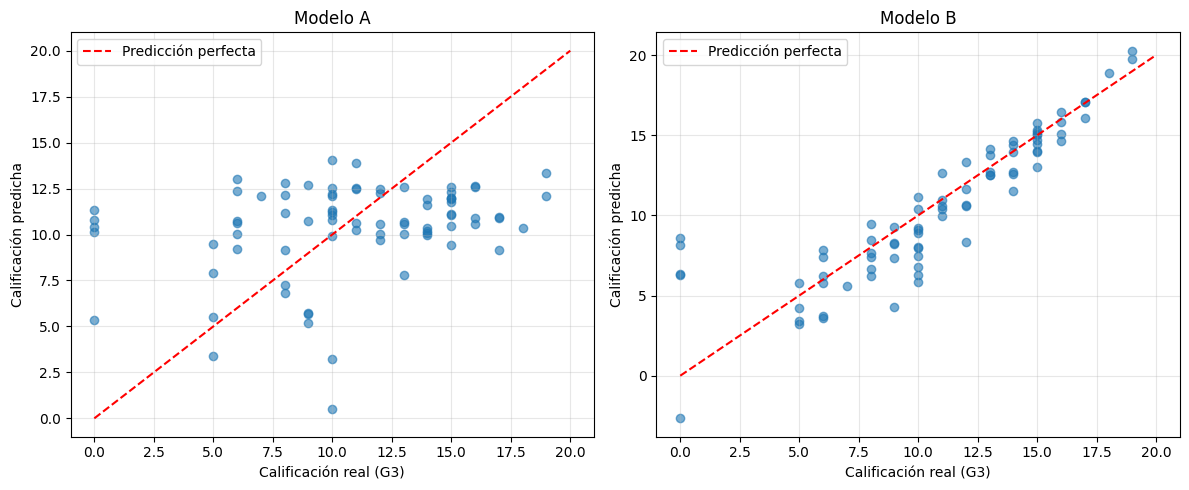

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, nombre in zip(
    axes,
    [pred_A, pred_B],
    ["Modelo A", "Modelo B"]
):
    ax.scatter(y_test, pred, alpha=0.6)

    ax.plot(
        [0, 20], [0, 20],
        "r--",
        label="Predicción perfecta"
    )

    ax.set_title(nombre)
    ax.set_xlabel("Calificación real (G3)")
    ax.set_ylabel("Calificación predicha")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [98]:
# Verificación del error absoluto medio
mae_A = mean_absolute_error(y_test, pred_A)
mae_B = mean_absolute_error(y_test, pred_B)

print("MAE Modelo A:", round(mae_A, 4))
print("MAE Modelo B:", round(mae_B, 4))

MAE Modelo A: 3.7323
MAE Modelo B: 1.4812


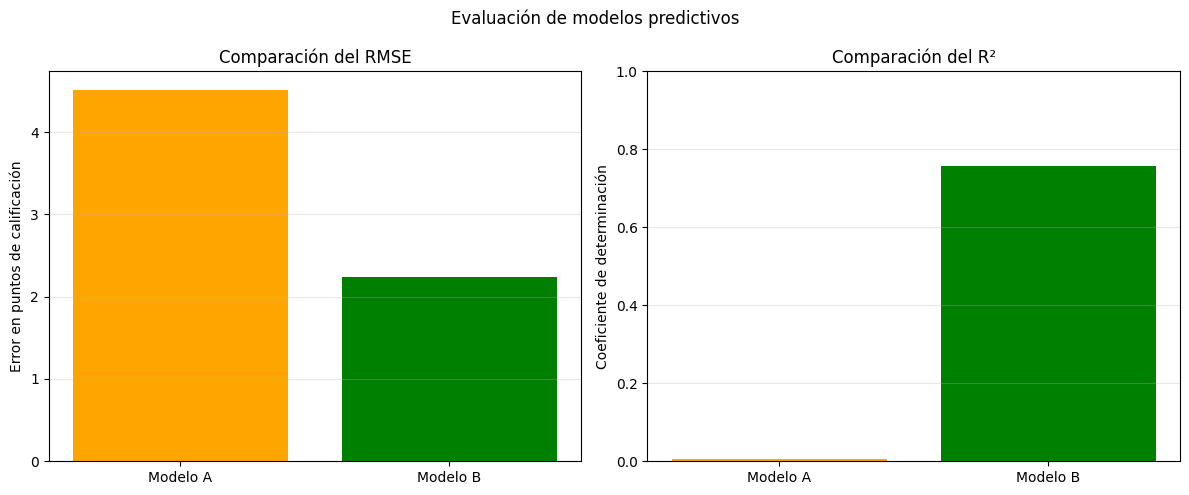

In [99]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Comparar RMSE
axes[0].bar(
    ["Modelo A", "Modelo B"],
    [4.5132, 2.2363],
    color=["orange", "green"]
)
axes[0].set_title("Comparación del RMSE")
axes[0].set_ylabel("Error en puntos de calificación")
axes[0].grid(axis="y", alpha=0.3)

# Comparar R²
axes[1].bar(
    ["Modelo A", "Modelo B"],
    [0.0066, 0.7561],
    color=["orange", "green"]
)
axes[1].set_title("Comparación del R²")
axes[1].set_ylabel("Coeficiente de determinación")
axes[1].set_ylim(0, 1)
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Evaluación de modelos predictivos")
plt.tight_layout()

plt.savefig(
    "comparacion_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Calificacion_real,Prediccion_Modelo_B,Error
0,10,5.84,4.16
1,12,11.63,0.37
2,5,3.22,1.78
3,10,8.05,1.95
4,9,8.24,0.76
5,13,12.73,0.27
6,18,18.87,-0.87
7,6,7.39,-1.39
8,0,6.28,-6.28
9,14,12.57,1.43


Error absoluto máximo: 8.5685
Predicciones fuera de 0 a 20: 2


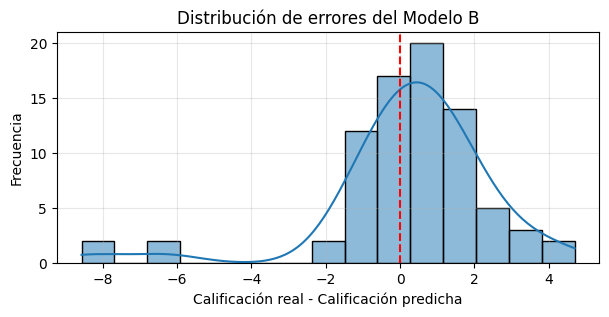

In [100]:
# Comparar valores reales y predicciones
comparacion = pd.DataFrame({
    "Calificacion_real": y_test.to_numpy(),
    "Prediccion_Modelo_B": pred_B,
    "Error": y_test.to_numpy() - pred_B
})

display(comparacion.head(10).round(2))

# Analizar errores
print("Error absoluto máximo:",
      round(comparacion["Error"].abs().max(), 4))

print("Predicciones fuera de 0 a 20:",
      ((pred_B < 0) | (pred_B > 20)).sum())

# Histograma de errores
plt.figure(figsize=(7, 3))

sns.histplot(
    comparacion["Error"],
    bins=15,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")
plt.title("Distribución de errores del Modelo B")
plt.xlabel("Calificación real - Calificación predicha")
plt.ylabel("Frecuencia")
plt.grid(alpha=0.3)

plt.savefig(
    "errores_modelo_B.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [101]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Modelo de referencia: predice la media
modelo_base = DummyRegressor(strategy="mean")

modelo_base.fit(X_A_train, y_train)

pred_base = modelo_base.predict(X_A_test)

# Evaluación
mae_base = mean_absolute_error(y_test, pred_base)
rmse_base = np.sqrt(
    mean_squared_error(y_test, pred_base)
)
r2_base = r2_score(y_test, pred_base)

print("MODELO DE REFERENCIA")
print("MAE:", round(mae_base, 4))
print("RMSE:", round(rmse_base, 4))
print("R²:", round(r2_base, 4))

MODELO DE REFERENCIA
MAE: 3.6459
RMSE: 4.5502
R²: -0.0097


In [102]:
tabla_final = pd.DataFrame([
    {
        "Modelo": "Referencia (media)",
        "MAE": mae_base,
        "RMSE": rmse_base,
        "R²": r2_base
    },
    {
        "Modelo": "A - Sin G1 y G2",
        "MAE": mean_absolute_error(y_test, pred_A),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, pred_A)
        ),
        "R²": r2_score(y_test, pred_A)
    },
    {
        "Modelo": "B - Con G1 y G2",
        "MAE": mean_absolute_error(y_test, pred_B),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, pred_B)
        ),
        "R²": r2_score(y_test, pred_B)
    }
])

display(tabla_final.round(4))

tabla_final.to_csv(
    "resultados_modelos.csv",
    index=False
)

,Modelo,MAE,RMSE,R²
0,Referencia (media),3.6459,4.5502,-0.0097
1,A - Sin G1 y G2,3.7323,4.5132,0.0066
2,B - Con G1 y G2,1.4812,2.2363,0.7561


In [103]:
from sklearn.model_selection import KFold, cross_validate

# Cinco particiones reproducibles
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metricas = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

def validar_modelo(nombre, modelo, X, y):

    scores = cross_validate(
        modelo,
        X,
        y,
        cv=cv,
        scoring=metricas,
        n_jobs=-1
    )

    mae = -scores["test_MAE"]
    rmse = -scores["test_RMSE"]
    r2 = scores["test_R2"]

    return {
        "Modelo": nombre,
        "MAE promedio": mae.mean(),
        "RMSE promedio": rmse.mean(),
        "R² promedio": r2.mean(),
        "Desv. R²": r2.std()
    }

validacion = pd.DataFrame([
    validar_modelo(
        "Modelo A",
        modelo_A,
        X_A_train,
        y_train
    ),
    validar_modelo(
        "Modelo B",
        modelo_B,
        X_B_train,
        y_train
    )
])

print("VALIDACIÓN CRUZADA (5 PARTICIONES)")
display(validacion.round(4))

VALIDACIÓN CRUZADA (5 PARTICIONES)


,Modelo,MAE promedio,RMSE promedio,R² promedio,Desv. R²
0,Modelo A,3.2845,4.3409,0.0468,0.1167
1,Modelo B,1.2656,1.8738,0.8260,0.0365


In [104]:
validacion.to_csv(
    "validacion_cruzada.csv",
    index=False
)

In [105]:
with open("requirements.txt", "w") as f:
    f.write(
        "pandas\n"
        "numpy\n"
        "matplotlib\n"
        "seaborn\n"
        "scikit-learn\n"
        "requests\n"
    )

print("Archivo requirements.txt creado")

Archivo requirements.txt creado


In [107]:
from google.colab import files

archivos = [
    "student_mat_limpio.csv",
    "resultados_modelos.csv",
    "validacion_cruzada.csv",
    "requirements.txt",
    "comparacion_modelos.png",
    "errores_modelo_B.png"
]

for archivo in archivos:
    files.download(archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>